In [36]:
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import LabelEncoder
import numpy as np
from PIL import Image
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report
from torchvision import models
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
train_df = pd.read_csv("train_split.csv")
test_df = pd.read_csv("test_split.csv")

In [3]:
le = LabelEncoder()
train_df["label"] = le.fit_transform(train_df["categories"])
test_df["label"] = le.transform(test_df["categories"])
train_df.head()

,ImgId,title,description,categories,path,label
0,B0002IXKP2,Natural Chemistry 3121 Pool Perfect Concentrat...,Pool Perfect is an all natural enzyme product ...,"Patio, Lawn & Garden",rpc/train/train/B0002IXKP2.jpg,16
1,B000CFB1QA,Lyle 16-Inch by 16-Inch See Your Stuff Clear S...,"Made of Clear 20-gauge vinyl, poly-tough duck ...","Arts, Crafts & Sewing",rpc/train/train/B000CFB1QA.jpg,3
2,B005LHFQLK,Samsung Chat GT-C3222 Unlocked GSM Cell Phone,If every phone is an investment into the futur...,All Electronics,rpc/train/train/B005LHFQLK.jpg,1
3,B00004W3ZQ,Legrand C210 Cord Mate II Kit,The Wiremold White Cordmate II kit contains ev...,Electronics,rpc/train/train/B00004W3ZQ.jpg,10
4,B00029J3CA,Dynomax 17734 Super Turbo Muffler,DynoMax Super Turbo performance mufflers exclu...,Automotive,rpc/train/train/B00029J3CA.jpg,4


In [4]:
images = []
for p in train_df["path"]:
      img = np.array(Image.open(p).convert("RGB"))
      images.append(img)

test_images = []
for p in test_df["path"]:
      img = np.array(Image.open(p).convert("RGB"))
      test_images.append(img)      

In [5]:
X_train = np.stack(images)
X_test = np.stack(test_images)

X_test.shape, X_train.shape

((8400, 100, 100, 3), (33600, 100, 100, 3))

In [6]:
X_train = torch.tensor(X_train).permute(0, 3, 1, 2)
X_test = torch.tensor(X_test).permute(0, 3, 1, 2)
X_test.shape, X_train.shape

(torch.Size([8400, 3, 100, 100]), torch.Size([33600, 3, 100, 100]))

In [7]:
del images, test_images

In [8]:
y_train = torch.tensor(train_df["label"].values)
y_test = torch.tensor(test_df["label"].values)
y_train.shape, y_test.shape

(torch.Size([33600]), torch.Size([8400]))

In [9]:
train_data = TensorDataset(X_train, y_train)
test_data = TensorDataset(X_test, y_test)

In [10]:
train_load = DataLoader(train_data, batch_size=64, shuffle=True)
test_load = DataLoader(test_data, batch_size=64)

In [15]:
model = nn.Sequential(
      nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      
      nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),
      
      nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
      nn.ReLU(),
      nn.MaxPool2d(2),

      nn.Flatten(),
      nn.Linear(18432, 256),
      nn.ReLU(),
      nn.Dropout(0.5),
      nn.Linear(256, 21)
)

In [16]:
device = "cuda"
model = model.to(device)

In [17]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_c = nn.CrossEntropyLoss()

In [18]:
for epoch in range(5):
      model.train()
      total_loss = 0

      for x, y in train_load:
            x = x.to(device).float()/255
            y = y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = loss_c(out, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

      print(epoch + 1, total_loss / len(train_load))      

1 2.9091904649280367
2 2.6714032073248
3 2.507631469454084
4 2.3628373155139744
5 2.2049478115354266


In [20]:
model.eval()
preds = []

with torch.no_grad():
    for x, y in test_load:
        x = x.to(device).float() / 255
        out = model(x)
        
        preds.append(out.argmax(1).cpu())

y_pred = torch.cat(preds).numpy()

In [21]:
print(classification_report(y_test, y_pred, target_names=le.classes_))

                           precision    recall  f1-score   support

               All Beauty       0.20      0.21      0.20       400
          All Electronics       0.18      0.20      0.19       400
               Appliances       0.24      0.34      0.28       400
    Arts, Crafts & Sewing       0.19      0.16      0.17       400
               Automotive       0.41      0.31      0.35       400
                     Baby       0.31      0.32      0.32       400
            Baby Products       0.29      0.17      0.22       400
                   Beauty       0.29      0.30      0.29       400
Cell Phones & Accessories       0.42      0.49      0.46       400
Clothing, Shoes & Jewelry       0.37      0.47      0.41       400
              Electronics       0.42      0.34      0.38       400
   Grocery & Gourmet Food       0.32      0.63      0.43       400
   Health & Personal Care       0.35      0.24      0.28       400
  Industrial & Scientific       0.25      0.18      0.21     

In [22]:
y_pred_cnn = y_pred

In [31]:
model = models.resnet18(weights="DEFAULT")
model.fc = nn.Linear(512,21)
model = model.to(device)

In [32]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
loss_c = nn.CrossEntropyLoss()
mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

In [33]:
for epoch in range(3):
      model.train()
      total_loss = 0

      for x, y in train_load:
            x = x.to(device).float()/255
            x = F.interpolate(x, size=224)
            x = (x - mean) / std
            y = y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = loss_c(out, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

      print(epoch + 1, total_loss / len(train_load))      

1 2.063980551220122
2 1.425978772753761
3 0.9120206928253174


In [34]:
model.eval()
preds = []

with torch.no_grad():
    for x, y in test_load:
        x = x.to(device).float() / 255
        x = F.interpolate(x, size=224)
        x = (x - mean) / std
        out = model(x)
        preds.append(out.argmax(1).cpu())

y_pred = torch.cat(preds).numpy()

In [35]:
print(classification_report(y_test, y_pred, target_names=le.classes_))

                           precision    recall  f1-score   support

               All Beauty       0.47      0.40      0.43       400
          All Electronics       0.36      0.37      0.37       400
               Appliances       0.54      0.50      0.52       400
    Arts, Crafts & Sewing       0.42      0.43      0.42       400
               Automotive       0.60      0.46      0.52       400
                     Baby       0.56      0.57      0.57       400
            Baby Products       0.56      0.34      0.42       400
                   Beauty       0.44      0.49      0.46       400
Cell Phones & Accessories       0.63      0.71      0.67       400
Clothing, Shoes & Jewelry       0.44      0.69      0.53       400
              Electronics       0.67      0.47      0.55       400
   Grocery & Gourmet Food       0.67      0.70      0.68       400
   Health & Personal Care       0.56      0.43      0.49       400
  Industrial & Scientific       0.36      0.38      0.37     

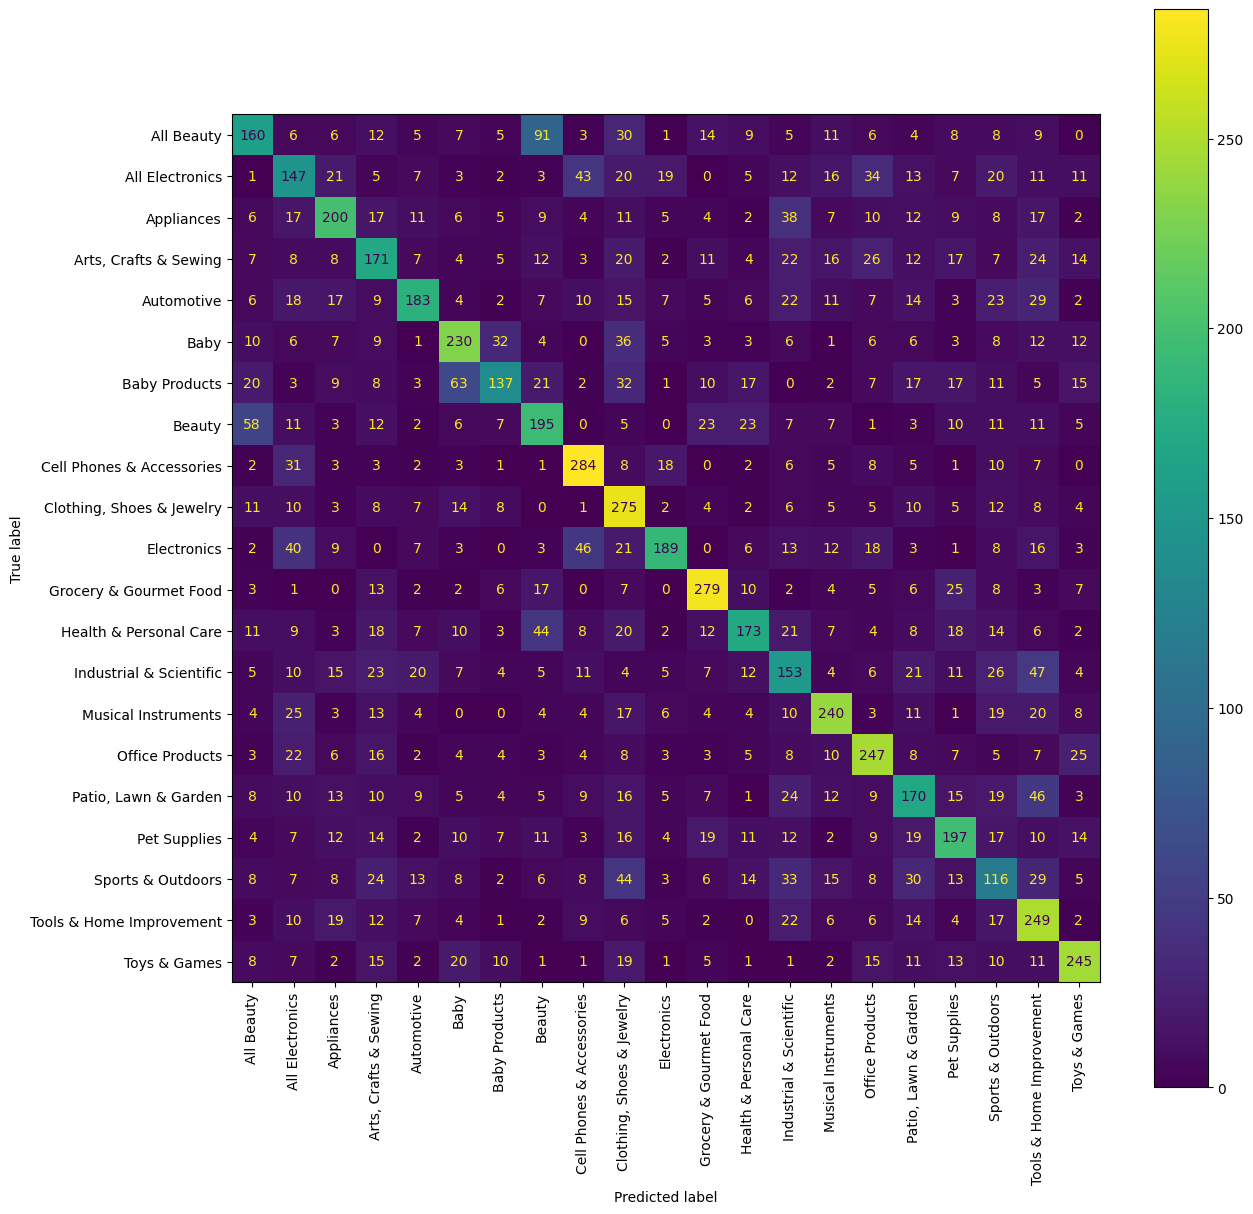

In [37]:
fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, xticks_rotation="vertical", display_labels=le.classes_)
plt.show()

In [ ]:
torch.save(model.state_dict(), "resnet.pt")